In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(pd.__version__)

3.0.5


In [6]:
df = pd.read_csv("vacancies.csv")
df.head()

,vacancy_id,salary_from,salary_to,experience,city,employment_type
0,37351176,60000.0,70000.0,Нет опыта,Екатеринбург,Удалённая работа
1,53503796,140000.0,210000.0,От 1 года до 3 лет,Москва,Полная занятость
2,20319022,NaN,NaN,Более 6 лет,Москва,Полная занятость
3,40619665,145000.0,215000.0,От 1 года до 3 лет,Нижний Новгород,Полная занятость
4,14675717,NaN,NaN,Более 6 лет,Москва,Полная занятость


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   vacancy_id       100000 non-null  int64  
 1   salary_from      68385 non-null   float64
 2   salary_to        69219 non-null   float64
 3   experience       100000 non-null  str    
 4   city             100000 non-null  str    
 5   employment_type  100000 non-null  str    
dtypes: float64(2), int64(1), str(3)
memory usage: 4.6 MB


In [8]:
df.describe()

,vacancy_id,salary_from,salary_to
count,1.000000e+05,6.838500e+04,6.921900e+04
mean,5.502163e+07,4.547105e+05,6.155720e+05
std,2.595831e+07,2.466358e+06,3.377744e+06
min,1.000028e+07,5.000000e+03,7.000000e+03
25%,3.250663e+07,8.500000e+04,1.100000e+05
50%,5.510610e+07,1.200000e+05,1.700000e+05
75%,7.749584e+07,1.900000e+05,2.600000e+05
max,9.999938e+07,5.950000e+07,8.950000e+07


In [33]:
# Удалим строки, где оба значения заработной платы не указаны, ведь они бесполезны для выполнения задания
df_clean = df.dropna(axis=0, how="all", subset=["salary_from", "salary_to"])
df_clean.info()

<class 'pandas.DataFrame'>
Index: 74410 entries, 0 to 99998
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   vacancy_id       74410 non-null  int64  
 1   salary_from      68385 non-null  float64
 2   salary_to        69219 non-null  float64
 3   experience       74410 non-null  str    
 4   city             74410 non-null  str    
 5   employment_type  74410 non-null  str    
dtypes: float64(2), int64(1), str(3)
memory usage: 4.0 MB


In [36]:
# Удалим строки с явными выбросами: значениями зарплат выше 1 млн. и меньше 30 тыс.
pd.set_option('display.float_format', '{:.1f}'.format)
df_clean = df_clean[
    ((df_clean['salary_from'].between(30000, 1000000)) | (df_clean['salary_from'].isna())) &
    ((df_clean['salary_to'].between(30000, 1000000)) | (df_clean['salary_to'].isna()))
]
df_clean.info()
df_clean.describe()

<class 'pandas.DataFrame'>
Index: 72287 entries, 0 to 99998
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   vacancy_id       72287 non-null  int64  
 1   salary_from      66267 non-null  float64
 2   salary_to        67109 non-null  float64
 3   experience       72287 non-null  str    
 4   city             72287 non-null  str    
 5   employment_type  72287 non-null  str    
 6   salary           72287 non-null  float64
dtypes: float64(3), int64(1), str(3)
memory usage: 4.4 MB


,vacancy_id,salary_from,salary_to,salary
count,72287.0,66267.0,67109.0,72287.0
mean,55067069.4,146459.8,199268.7,173039.7
std,25967268.2,91318.2,127198.0,109336.9
min,10000279.0,30000.0,30000.0,30000.0
25%,32576108.0,85000.0,110000.0,95000.0
50%,55155707.0,120000.0,170000.0,145000.0
75%,77621451.5,185000.0,250000.0,220000.0
max,99999380.0,875000.0,920000.0,880000.0


In [41]:
def get_salary(row):
    if pd.notna(row['salary_from']) and pd.notna(row['salary_to']):
        return (row['salary_from'] + row['salary_to']) / 2
    elif pd.notna(row['salary_from']):
        return row['salary_from']
    elif pd.notna(row['salary_to']):
        return row['salary_to']

df_clean['salary'] = df_clean.apply(get_salary, axis=1)

descriptions = []

experience_levels = df_clean['experience'].unique()

for exp in experience_levels:
    desc = df_clean[df_clean['experience'] == exp]['salary'].describe()
    descriptions.append(desc)

table = pd.concat(descriptions, axis=1, keys=experience_levels)
table = table.T
table = table.round(1)

print(table)

                     count     mean      std     min      25%      50%  \
Нет опыта          13903.0  78622.2  21310.9 30000.0  60000.0  77500.0   
От 1 года до 3 лет 33237.0 180580.9 112053.9 37500.0 110000.0 147500.0   
От 3 до 6 лет      18942.0 176574.0  68261.2 30000.0 125000.0 170000.0   
Более 6 лет         6205.0 333409.3 103619.9 65000.0 255000.0 327500.0   

                        75%      max  
Нет опыта           95000.0 155000.0  
От 1 года до 3 лет 207500.0 880000.0  
От 3 до 6 лет      222500.0 495000.0  
Более 6 лет        405000.0 765000.0  


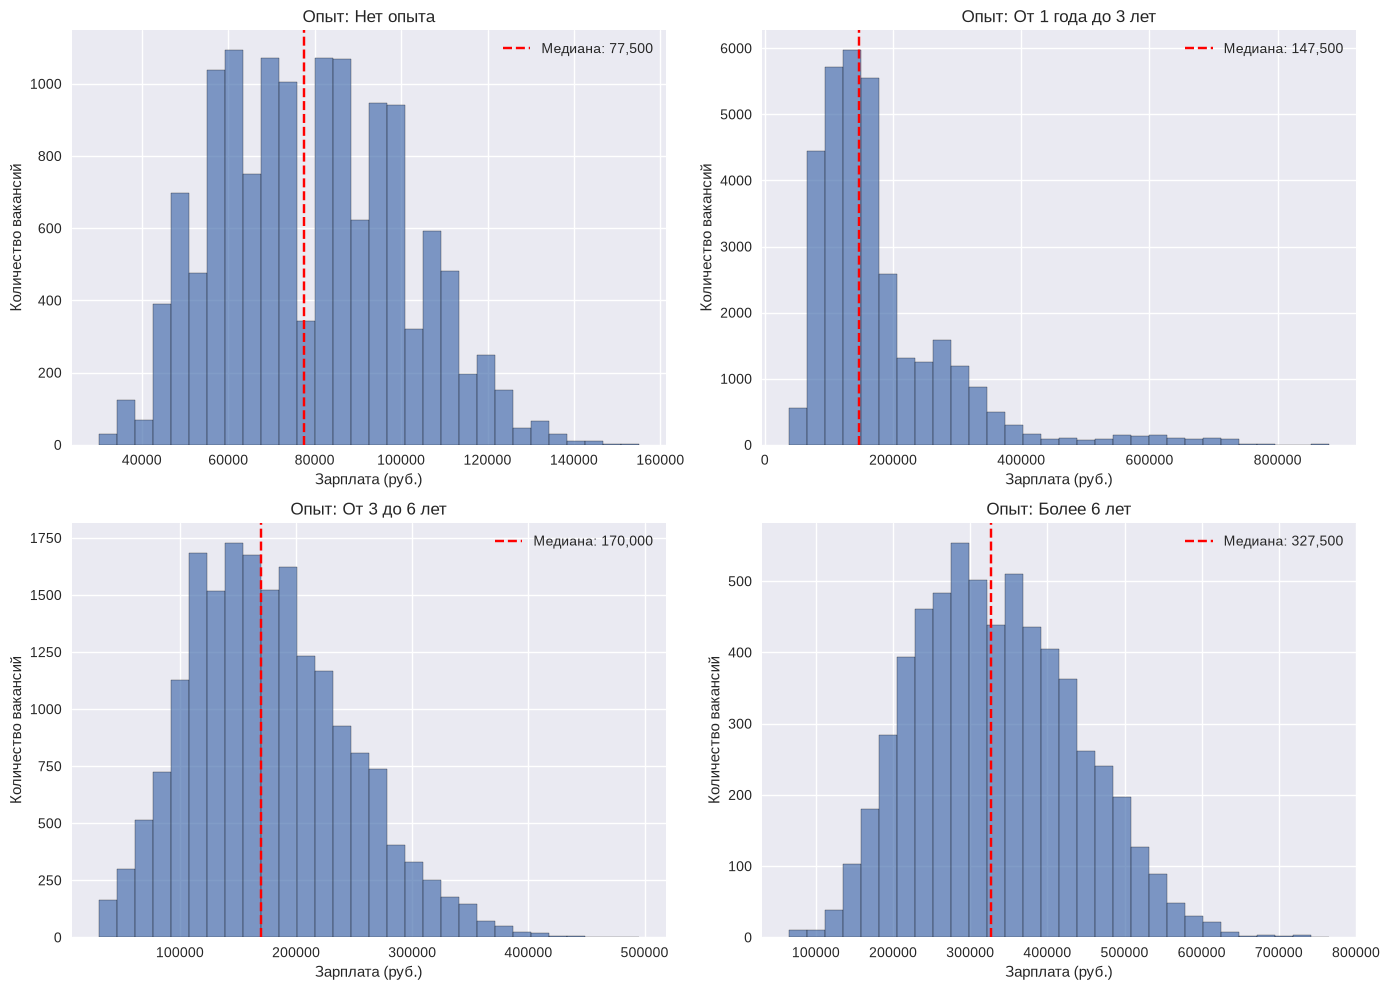

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, level in enumerate(experience_levels):

    data = df_clean[df_clean['experience'] == level]['salary']
    
    axes[i].hist(data, bins=30, edgecolor='black', alpha=0.7)
    axes[i].set_title(f'Опыт: {level}')
    axes[i].set_xlabel('Зарплата (руб.)')
    axes[i].set_ylabel('Количество вакансий')
    axes[i].axvline(data.median(), color='red', linestyle='--', label=f'Медиана: {data.median():,.0f}')
    axes[i].legend()

plt.tight_layout()
plt.show()

In [40]:
for exp in experience_levels:
    data = df_clean[df_clean['experience'] == exp]['salary']
    skew = data.skew()
    print(f"{exp}: {skew:.2f}")

Нет опыта: 0.25
От 1 года до 3 лет: 2.28
От 3 до 6 лет: 0.49
Более 6 лет: 0.33


In [43]:
print(table["75%"] - table["25%"])

Нет опыта             35000.0
От 1 года до 3 лет    97500.0
От 3 до 6 лет         97500.0
Более 6 лет          150000.0
dtype: float64
